# Boundary stabilization of a sedimentation front by forwarding

Companion notebook to the paper. It reproduces, from scratch, every number of
Section 6: the operating point, the forwarding design, the small-gain condition,
and the exact closed-loop spectrum.

Running time is about three minutes on a free Colab CPU. Nothing here needs a
GPU, and no data file is used: the operating point is defined by eight physical
constants.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Vincent69410/sedimentation-forwarding/blob/main/notebooks/worked_example.ipynb)

## 0. Setup

On Colab, the cell below clones the repository. Locally, it does nothing.

In [1]:
import os, sys, subprocess

if "google.colab" in sys.modules:
    if not os.path.isdir("sedimentation-forwarding"):
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/Vincent69410/sedimentation-forwarding.git"], check=True)
    sys.path.insert(0, "sedimentation-forwarding")
else:
    sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import sedimentation_forwarding as sf

np.seterr(all="ignore")
print("sedimentation_forwarding", sf.__version__)

sedimentation_forwarding 1.0.0


## 1. The operating point

A column of depth $z_b = 1$ m is fed at the top with a suspension of silica
grains, $\rho_s = 2650\ \mathrm{kg/m^3}$, of diameter $0.5$ mm, at the solid
fraction $\varepsilon_{in} = 0.11$, and drained at the bottom by a pump whose
velocity $v_m$ is the control.

Everything else follows. The apparent gravity is
$K = g(\rho_s - \rho_f)/\rho_s$. The relaxation rate $\gamma$ is a parameter
of the model, not a drag law: it is fixed by requiring that the free-settling
velocity $K/\gamma$ equal the terminal velocity of an isolated grain. Above the
random loose packing fraction $\varepsilon_c = 0.55$ the grains are in contact
and carry an effective stress, taken as a power law of exponent $n_s = 5$ and
scale $\sigma_0 = 10^5$ Pa.

In [2]:
P = sf.worked_example()        # solves the shooting problem and the pole equation

rho_s, d = 2650.0, 5e-4
v0 = sf.examples.terminal_velocity(rho_s, d)
print(f"K          = {P.K:.4f} m/s^2")
print(f"v_0        = {v0:.5e} m/s   (Re = {sf.examples.reynolds():.1f})")
print(f"gamma      = {P.gam:.2f} s^-1")
print(f"eps_in     = {P.eps_in:.4f}")
print(f"bed L      = {P.zb - P.zs:.3f} m")

K          = 6.1081 m/s^2
v_0        = 7.84474e-02 m/s   (Re = 39.2)
gamma      = 77.86 s^-1
eps_in     = 0.1100
bed L      = 0.020 m


The physically meaningful stiffness is not $\sigma_0$ but the compressive
modulus it produces at the operating point, $\rho_s c_s^2$, and the load the bed
actually carries is its buoyant weight.

In [3]:
modulus = rho_s * P.cs[0] ** 2
weight = (rho_s - 1000.0) * 9.81 * P.e.mean() * (P.zb - P.zs)
print(f"compressive modulus rho_s cs^2 = {modulus:.3e} Pa  ({modulus/1e6:.2f} MPa)")
print(f"stress at the base of the bed  = {float(P.S(P.e[-1])) * rho_s:.1f} Pa")
print(f"buoyant weight of the bed      = {weight:.1f} Pa")
print(f"solids loading                 = {P.eps_in * P.lam * rho_s * 3.6:.1f} t/m2/h")

compressive modulus rho_s cs^2 = 9.091e+05 Pa  (0.91 MPa)
stress at the base of the bed  = 180.3 Pa
buoyant weight of the bed      = 178.1 Pa
solids loading                 = 102.9 t/m2/h


## 2. Table 1: the design

The underflow $v_m^*$ comes from a scalar shooting; the design then evaluates
the interface gain $\mathbf{G}_o$, solves the pole equation $c = \mathcal{F}(c)$
and builds the Sylvester kernel.

In [4]:
rows = [
    ("Underflow velocity (shooting)",            "v_m*",        P.vm,       "m/s"),
    ("Free-settling speed",                      "lambda",      P.lam,      "m/s"),
    ("Interface jump",                           "[eps*]",      P.jump,     "-"),
    ("Compression eigenvalue lambda_3 at zs*",   "l3(zs*)",     P.l3s,      "m/s"),
    ("Compression eigenvalue lambda_4 at zs*",   "l4(zs*)",     P.l4s,      "m/s"),
    ("Compression eigenvalue lambda_3 at zb",    "l3(zb)",      P.l3b,      "m/s"),
    ("Compression eigenvalue lambda_4 at zb",    "l4(zb)",      P.l4b,      "m/s"),
    ("Interface reflection coefficient",         "-k^2",        -P.k ** 2,  "-"),
    ("Geometric decay ceiling",                  "mu2bar",      P.mu2bar,   "1/m"),
    ("Free-settling transit",                    "T_1",         P.zs/P.lam, "s"),
    ("Transmission pole",                        "c*",          P.cstar,    "1/s"),
    ("Non-resonance functional",                 "Delta_z",     P.Dz,       "-"),
    ("Velocity factor",                          "gamma_v",     P.gv,       "-"),
    ("Input gain",                               "G",           P.G,        "-"),
]
for name, sym, val, unit in rows:
    print(f"{name:<42}{sym:>10}  {val: .6e}  {unit}")

Underflow velocity (shooting)                   v_m*   1.960302e-02  m/s
Free-settling speed                           lambda   9.805041e-02  m/s
Interface jump                                [eps*]   4.400025e-01  -
Compression eigenvalue lambda_3 at zs*       l3(zs*)   1.854147e+01  m/s
Compression eigenvalue lambda_4 at zs*       l4(zs*)  -1.850225e+01  m/s
Compression eigenvalue lambda_3 at zb         l3(zb)   1.855465e+01  m/s
Compression eigenvalue lambda_4 at zb         l4(zb)  -1.851544e+01  m/s
Interface reflection coefficient                -k^2  -9.957740e-01  -
Geometric decay ceiling                       mu2bar   5.290921e-02  1/m
Free-settling transit                            T_1   9.994859e+00  s
Transmission pole                                 c*  -4.358965e-04  1/s
Non-resonance functional                     Delta_z   1.995064e+00  -
Velocity factor                              gamma_v   9.997776e-01  -
Input gain                                         G   1.0002

## 3. Condition 17

The small-gain condition is a joint feasibility problem in the weights of the
Lyapunov functional, and must be solved as one. `best` sweeps the pair
$(\mu_2, r)$ over the window where the boundary dissipation coefficients
$d_1, d_4$ are positive, the other weights being sent to their useful limit.

In [5]:
b = sf.best(P, ngrid=14)

print(f"mu_2 / mu2bar = {b['mu2'] / P.mu2bar:.4f}")
print(f"r = p4/p3     = {b['r']:.6f}")
print()
print(f"alphabar      = {b['alphabar']:.4f}")
print(f"a_eta         = {b['aeta']:.4e}   (chi = {b['chi']:.3e},"
      f" J_L = {b['JL']:.3e}, I_eta = {b['Ieta']:.3e})")
print(f"a_o           = {b['ao']:.4e}   (Sigma_b = {b['Sigma_b']:.3e},"
      f" I_o = {b['Io']:.3e})")
print(f"d_1, d_4      = {b['d1']:.3e}, {b['d4']:.3e}")
print()
print(f"(a_eta + a_o) / alphabar = {b['ratio']:.4f}"
      f"    {'SATISFIED' if b['ratio'] < 1 else 'VIOLATED'}"
      f"   (factor {1 / b['ratio']:.1f} to spare)")
print(f"certified rate  beta <= {b['margin']:.4e} s^-1")

mu_2 / mu2bar = 0.7585
r = p4/p3     = 1.000490

alphabar      = 1.4849
a_eta         = 4.1246e-01   (chi = 4.359e-04, J_L = 2.066e-01, I_eta = 8.216e-01)
a_o           = 1.2175e-01   (Sigma_b = 3.814e+05, I_o = 3.193e-07)
d_1, d_4      = 9.805e+12, 1.851e-02

(a_eta + a_o) / alphabar = 0.3598    SATISFIED   (factor 2.8 to spare)
certified rate  beta <= 9.5074e-01 s^-1


$d_4$ is the difference of two nearly equal numbers, which is why the sweep is
carried out on quantities computed to twelve digits.

In [6]:
L = P.zb - P.zs
t1 = b['r'] * np.exp(-2 * b['mu2'] * L) * abs(P.l4s)
t2 = P.l3s * (1 + b['nui']) * P.k ** 2
print(f"d_4 = {t1:.8f} - {t2:.8f} = {t1 - t2:.6e}")

d_4 = 18.48162160 - 18.46311393 = 1.850768e-02


## 4. The characteristic determinant

The design predicts a number: the transmission pole $c^*$ must be an eigenvalue
of the open-loop generator. We check it against a computation that shares only
the stationary profile and the propagator: the zeros of a $5 \times 5$
determinant built from the resolvent, with the generator nowhere discretized.

In [7]:
print(f"{'propagator steps':>18}   {'zero of det D':>22}")
for nst in (250, 500, 800):
    sp = sf.Spec(P, nst=nst)
    print(f"{nst:>18}   {np.real(sp.newton(P.cstar * 1.02)):>22.12e}")
print(f"{'fixed point':>18}   {P.cstar:>22.12e}")

  propagator steps            zero of det D
               250      -4.358965185737e-04
               500      -4.358965185741e-04


               800      -4.358965185746e-04
       fixed point      -4.358965185739e-04


## 5. Closing the loop moves that zero to $-\kappa$

The feedback is $u = \mathfrak{K} w$ with $\mathfrak{K} = -(c^* + \kappa)/G$.
The real zero of $\det D$ nearest $-\kappa$ should be $-\kappa$ exactly.

In [8]:
sp = sf.Spec(P, nst=500)
kappas = np.geomspace(3.16e-2, 1.0, 9)
err = []
for kap in kappas:
    Kg = sp.gain(kap)
    r = sp.newton(-kap * 1.00002, "forwarding", Kg)
    r = sp.newton(r, "forwarding", Kg)
    err.append(abs(np.real(r) / (-kap) - 1.0))
err = np.array(err)
for kap, e in zip(kappas, err):
    print(f"kappa = {kap:8.4f}   relative error {e:.2e}")
print(f"\nworst case: {err.max():.2e}")

kappa =   0.0316   relative error 3.45e-11
kappa =   0.0487   relative error 3.47e-11
kappa =   0.0749   relative error 3.48e-11
kappa =   0.1154   relative error 3.48e-11
kappa =   0.1778   relative error 3.49e-11
kappa =   0.2738   relative error 3.49e-11
kappa =   0.4216   relative error 3.49e-11
kappa =   0.6493   relative error 3.49e-11
kappa =   1.0000   relative error 3.46e-11

worst case: 3.49e-11


## 6. No other eigenvalue to the right of $-3$

Counting zeros of $\det D$ by the argument principle on rectangular contours.
The determinant must be used raw here: any normalization of the matrix rows is
non-analytic and corrupts the winding number.

In [9]:
def winding(sp, Kg, re_min, re_max, im_max, npt=1600):
    """Number of zeros of det D inside the rectangle, by the argument principle."""
    t = np.linspace(0, 1, npt)
    sides = [re_min + (re_max - re_min) * t - 1j * im_max,
             re_max + 1j * (-im_max + 2 * im_max * t),
             re_max + (re_min - re_max) * t + 1j * im_max,
             re_min + 1j * (im_max - 2 * im_max * t)]
    phase = []
    for side in sides:
        for s in side:
            y1s, _, j1 = sp.omega1(s)
            phase.append(np.angle(np.linalg.det(
                sp.det_with(s, y1s, j1, "forwarding", Kg))))
    u = np.unwrap(np.array(phase))
    return (u[-1] - u[0]) / (2 * np.pi)


sp = sf.Spec(P, nst=250)
for kap in (3.16e-2, 3.16e-1):
    Kg = sp.gain(kap)
    n_right = winding(sp, Kg, -1e-9, 5.0, 30.0)
    n_band = winding(sp, Kg, -3.0, -1e-9, 30.0)
    print(f"kappa = {kap:7.4f}:  # zeros in Re s > 0 : {n_right:+.3f}"
          f"     # zeros in [-3,0] x [-30,30] : {n_band:+.3f}")

kappa =  0.0316:  # zeros in Re s > 0 : +0.000     # zeros in [-3,0] x [-30,30] : +1.000


kappa =  0.3160:  # zeros in Re s > 0 : +0.000     # zeros in [-3,0] x [-30,30] : +1.000


The single zero of the second box is the placed pole. The spectral abscissa of
the closed loop is therefore exactly $-\kappa$ on this range.

## 7. Figure 2

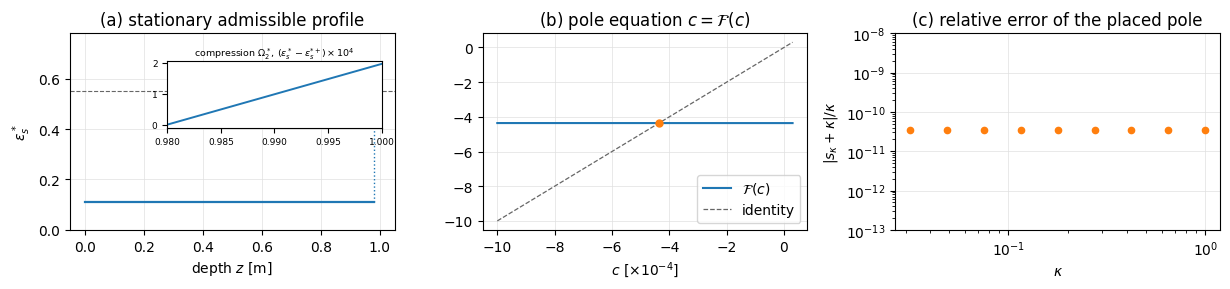

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(12.4, 3.0))

z1 = np.linspace(0, P.zs, 200)
ax[0].plot(z1, np.full_like(z1, P.eps_in), lw=1.6, color="C0")
ax[0].plot(P.xg, P.e, lw=1.6, color="C0")
ax[0].plot([P.zs, P.zs], [P.eps_in, P.ep], lw=1.0, ls=":", color="C0")
ax[0].axhline(P.eps_c, lw=0.8, ls="--", color="0.4")
ax[0].set_xlabel("depth $z$ [m]"); ax[0].set_ylabel(r"$\varepsilon_s^*$")
ax[0].set_title("(a) stationary admissible profile"); ax[0].set_ylim(0, 0.78)
ins = ax[0].inset_axes([0.30, 0.52, 0.66, 0.34])
ins.plot(P.xg, (P.e - P.ep) * 1e4, lw=1.4, color="C0")
ins.set_xlim(P.zs, P.zb); ins.tick_params(labelsize=6.5)
ins.set_title(r"compression $\Omega_2^*$, $(\varepsilon_s^*-\varepsilon_s^{*+})"
              r"\times10^{4}$", fontsize=6.8, pad=2.5)

cg = np.linspace(-1.0e-3, 3e-5, 70)
Fv = [P.design(c)["F"] for c in cg]
ax[1].plot(cg * 1e4, np.array(Fv) * 1e4, lw=1.5, color="C0", label=r"$\mathcal{F}(c)$")
ax[1].plot(cg * 1e4, cg * 1e4, lw=0.9, ls="--", color="0.4", label="identity")
ax[1].plot([P.cstar * 1e4], [P.cstar * 1e4], "o", color="C1", ms=5)
ax[1].set_xlabel(r"$c\ [\times 10^{-4}]$")
ax[1].set_title(r"(b) pole equation $c=\mathcal{F}(c)$"); ax[1].legend(loc="lower right")

ax[2].loglog(kappas, np.maximum(err, 1e-15), "o", color="C1", ms=4.5)
ax[2].set_xlabel(r"$\kappa$"); ax[2].set_ylabel(r"$|s_\kappa+\kappa|/\kappa$")
ax[2].set_ylim(1e-13, 1e-8)
ax[2].set_title("(c) relative error of the placed pole")

for a in ax:
    a.grid(True, color="0.88", lw=0.5)
fig.tight_layout()
plt.show()

## 8. Explore

`settling_column` takes the physical parameters directly. The feasibility of
Condition 17 is governed by the stiffness of the bed and by its thickness: the
cell below sweeps the stress scale.

In [11]:
print(f"{'sigma_0 [Pa]':>14}{'modulus [MPa]':>16}{'ratio':>10}")
for sigma_0 in (1e4, 3e4, 1e5, 3e5, 1e6):
    Q = sf.settling_column(sigma_0=sigma_0, Nd=500)
    if not Q.ok or Q.solve_cstar() is None:
        continue
    c = sf.best(Q, ngrid=8)   # coarser sweep than the paper; 0.36 here vs 0.3598 at ngrid=14
    print(f"{sigma_0:14.0e}{rho_s * Q.cs[0] ** 2 / 1e6:16.3f}{c['ratio']:10.4f}")

  sigma_0 [Pa]   modulus [MPa]     ratio


         1e+04           0.091    1.6873


         3e+04           0.273    0.7886


         1e+05           0.909    0.3634


         3e+05           2.727    0.1819


         1e+06           9.091    0.0902


The condition fails below about $0.45$ MPa of compressive modulus. The bed
thickness acts the same way; `settling_column(L=...)` sweeps it.

---

If you use this code, please cite the paper.